In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, f1_score, roc_curve, roc_auc_score, auc

%matplotlib inline

In [2]:
data = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv'

df = pd.read_csv(data)

df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [3]:
df.dtypes

lead_source                     str
industry                        str
employment_status               str
location                        str
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

In [4]:
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [5]:
categorical = []
numerical = []

for i in df.columns:
    if df[i].dtypes == 'str':
        categorical_columns = categorical.append(i)
    if df[i].dtypes != 'str':
        numerical_columns = numerical.append(i)

In [6]:
categorical

['lead_source', 'industry', 'employment_status', 'location']

In [7]:
numerical

['annual_income',
 'number_of_courses_viewed',
 'interaction_count',
 'lead_score',
 'converted']

In [8]:
df[categorical] = df[categorical].fillna('NA')

df[numerical] = df[numerical].fillna(0.0)

df.isnull().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

In [9]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

In [10]:
df_full_train, df_test = train_test_split(df, test_size = 0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size = 0.25, random_state=1)

In [11]:
df['converted'].unique()

array([1, 0])

In [12]:
df_train

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
4740,paid_ads,technology,employed,asia,80198.0,5,9,0.91,1
1452,paid_ads,retail,employed,asia,50548.0,2,5,0.48,0
2846,NA,finance,employed,NA,76300.0,0,3,0.42,0
4670,paid_ads,finance,employed,NA,80371.0,2,6,0.49,0
168,organic_search,finance,employed,asia,73567.0,2,4,0.48,1
...,...,...,...,...,...,...,...,...,...
253,paid_ads,finance,employed,north_america,84573.0,2,3,0.37,1
1366,events,technology,employed,asia,85051.0,1,3,0.56,0
753,events,retail,unemployed,asia,21561.0,0,1,0.17,0
4990,organic_search,healthcare,unemployed,south_america,31691.0,3,5,0.49,1


In [13]:
y_train = df_train['converted'].values
y_val = df_val['converted'].values
y_test = df_test['converted'].values

del df_train['converted']
del df_val['converted']
del df_test['converted']

In [14]:
numerical = ['annual_income',
 'number_of_courses_viewed',
 'interaction_count',
 'lead_score']

auc_scores = []

for numerical_features in numerical:
    auc = roc_auc_score(y_train, df_train[numerical_features])
    
    auc_scores.append((numerical_features, auc))

auc_df = pd.DataFrame(auc_scores, columns=['Numerical_features', 'AUC'])

auc_df.sort_values(by='AUC', ascending=False)

,Numerical_features,AUC
3,lead_score,0.788225
2,interaction_count,0.764920
1,number_of_courses_viewed,0.722989
0,annual_income,0.608198


In [15]:
categorical = ['lead_source', 'industry', 'employment_status', 'location']

In [16]:
df_train[categorical + numerical]

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score
4740,paid_ads,technology,employed,asia,80198.0,5,9,0.91
1452,paid_ads,retail,employed,asia,50548.0,2,5,0.48
2846,NA,finance,employed,NA,76300.0,0,3,0.42
4670,paid_ads,finance,employed,NA,80371.0,2,6,0.49
168,organic_search,finance,employed,asia,73567.0,2,4,0.48
...,...,...,...,...,...,...,...,...
253,paid_ads,finance,employed,north_america,84573.0,2,3,0.37
1366,events,technology,employed,asia,85051.0,1,3,0.56
753,events,retail,unemployed,asia,21561.0,0,1,0.17
4990,organic_search,healthcare,unemployed,south_america,31691.0,3,5,0.49


In [17]:
train_dict = df_train[categorical + numerical].to_dict(orient='records')
dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dict)

model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)

,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalt

In [18]:
val_dict = df_val[categorical + numerical].to_dict(orient='records')
X_val = dv.transform(val_dict)

In [19]:
y_pred = model.predict_proba(X_val)[:, 1]

auc = roc_auc_score(y_val, y_pred)
print(round(auc, 3))

0.732


In [20]:
np.linspace(0, 1, 101)

array([0.  , 0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.08, 0.09, 0.1 ,
       0.11, 0.12, 0.13, 0.14, 0.15, 0.16, 0.17, 0.18, 0.19, 0.2 , 0.21,
       0.22, 0.23, 0.24, 0.25, 0.26, 0.27, 0.28, 0.29, 0.3 , 0.31, 0.32,
       0.33, 0.34, 0.35, 0.36, 0.37, 0.38, 0.39, 0.4 , 0.41, 0.42, 0.43,
       0.44, 0.45, 0.46, 0.47, 0.48, 0.49, 0.5 , 0.51, 0.52, 0.53, 0.54,
       0.55, 0.56, 0.57, 0.58, 0.59, 0.6 , 0.61, 0.62, 0.63, 0.64, 0.65,
       0.66, 0.67, 0.68, 0.69, 0.7 , 0.71, 0.72, 0.73, 0.74, 0.75, 0.76,
       0.77, 0.78, 0.79, 0.8 , 0.81, 0.82, 0.83, 0.84, 0.85, 0.86, 0.87,
       0.88, 0.89, 0.9 , 0.91, 0.92, 0.93, 0.94, 0.95, 0.96, 0.97, 0.98,
       0.99, 1.  ])

In [21]:
thresholds = np.linspace(0, 1, 101) 

scores = []

for t in thresholds:
    actual_positive = (y_val == 1)
    predicted_positive = (y_pred >= t)

    tp = (actual_positive & predicted_positive).sum()
    fp = (~actual_positive & predicted_positive).sum()
    fn = (actual_positive & ~predicted_positive).sum()

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0 

    scores.append((t, precision, recall))


df_scores = pd.DataFrame(
    scores,
    columns = ['threshold', 'precision', 'recall']
)

df_scores

,threshold,precision,recall
0,0.00,0.586,1.000000
1,0.01,0.586,1.000000
2,0.02,0.586,1.000000
3,0.03,0.586,1.000000
4,0.04,0.586,1.000000
...,...,...,...
96,0.96,1.000,0.001706
97,0.97,0.000,0.000000
98,0.98,0.000,0.000000
99,0.99,0.000,0.000000


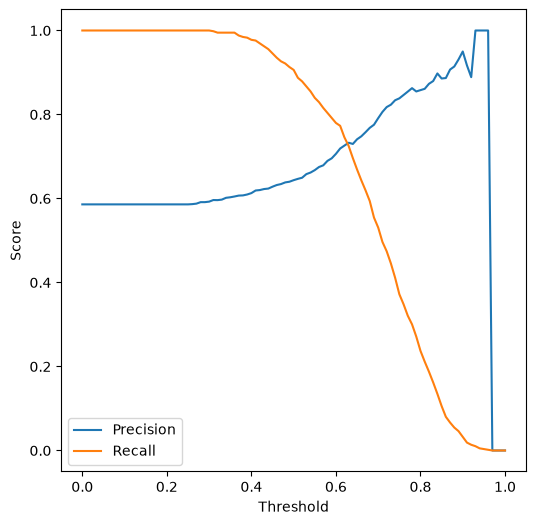

In [22]:
plt.figure(figsize=(6,6))

plt.plot(df_scores.threshold, df_scores.precision, label='Precision')
plt.plot(df_scores.threshold, df_scores.recall, label='Recall')

plt.xlabel('Threshold')
plt.ylabel('Score')
plt.legend()
plt.show()

In [23]:
df_scores['F1'] = 2 * (df_scores.precision * df_scores.recall) / (df_scores.precision + df_scores.recall)

df_scores['F1'] = df_scores['F1'].fillna(0)

df_scores[::10]

,threshold,precision,recall,F1
0,0.0,0.586000,1.000000,0.738966
10,0.1,0.586000,1.000000,0.738966
20,0.2,0.586000,1.000000,0.738966
30,0.3,0.592518,1.000000,0.744127
40,0.4,0.612834,0.977816,0.753452
50,0.5,0.643636,0.906143,0.752658
60,0.6,0.706337,0.779863,0.741281
70,0.7,0.791349,0.530717,0.635342
80,0.8,0.858025,0.237201,0.371658
90,0.9,0.950000,0.032423,0.062706


In [24]:
best_row = df_scores.loc[df_scores['F1'].idxmax()]

In [25]:
best_row

threshold    0.410000
precision    0.619048
recall       0.976109
F1           0.757616
Name: 41, dtype: float64

In [43]:
def train(df_train, y_train, C):
    dicts = df_train[categorical + numerical].to_dict(orient='records')

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X_train, y_train)

    return dv, model

In [38]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1)

scores = []

for train_idx, val_idx in kfold.split(df_full_train):

    df_train = df_full_train.iloc[train_idx]
    df_val = df_full_train.iloc[val_idx]

    y_train = df_train['converted']
    y_val = df_val['converted']

    del df_train['converted']
    del df_val['converted']

    dv, model = train(df_train, y_train)

    val_dicts = df_val[categorical + numerical].to_dict(orient='records')
    X_val = dv.transform(val_dicts)

    y_pred = model.predict_proba(X_val)[:, 1]

    auc = roc_auc_score(y_val, y_pred)

    scores.append(auc) 

print("AUC scores:",  scores)
print("Mean AUC:", round(np.mean(scores),3))
print("Standard deviation:", round(np.std(scores), 3))

AUC scores: [0.7305601027122453, 0.7295726148196622, 0.7363428071259397, 0.7412454717957564, 0.7209138590326581]
Mean AUC: 0.732
Standard deviation: 0.007


In [46]:
for C in [0.000001, 0.001, 1]:
    kfold = KFold(n_splits=5, shuffle=True, random_state=1)

    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):

        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]

        y_train = df_train['converted']
        y_val = df_val['converted']

        del df_train['converted']
        del df_val['converted']

        dv, model = train(df_train, y_train, C=C)

        val_dicts = df_val[categorical + numerical].to_dict(orient='records')
        X_val = dv.transform(val_dicts)

        y_pred = model.predict_proba(X_val)[:, 1]

        auc = roc_auc_score(y_val, y_pred)

        scores.append(auc) 

    print("C:", C)
    print("AUC scores:",  scores)
    print("Mean AUC:", round(np.mean(scores),3))
    print("Standard deviation:", round(np.std(scores), 3))

C: 1e-06
AUC scores: [0.5941004654148612, 0.6402137243565715, 0.6001570384100505, 0.6364466933726896, 0.6127532038032245]
Mean AUC: 0.617
Standard deviation: 0.019
C: 0.001
AUC scores: [0.7504349221633766, 0.7475333388395098, 0.7583539285346514, 0.7584127166669861, 0.7311259818106656]
Mean AUC: 0.749
Standard deviation: 0.01
C: 1
AUC scores: [0.7305601027122453, 0.7295726148196622, 0.7363428071259397, 0.7412454717957564, 0.7209138590326581]
Mean AUC: 0.732
Standard deviation: 0.007
